In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 37.9 MB/s  0:00:02


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import re
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("Student_Performance.csv")

In [4]:
df.head()

,Unnamed: 0,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [5]:
df.shape

(10000, 6)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Unnamed: 0                        10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [7]:
df.describe()

,Unnamed: 0,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [8]:
df.columns

Index(['Unnamed: 0', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

In [9]:
df.duplicated().sum()

np.int64(132)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.isnull().sum().sort_values(ascending=False).head()

,0
Sample Question Papers Practiced,2778
Extracurricular Activities,1563
Previous Scores,0
Unnamed: 0,0
Sleep Hours,0


In [12]:
from sklearn.impute import SimpleImputer
imputer_cat = SimpleImputer(strategy='most_frequent')
df[['Extracurricular Activities']] = imputer_cat.fit_transform(df[['Extracurricular Activities']])

In [13]:
df.drop(['Sample Question Papers Practiced'], axis=1, inplace=True)

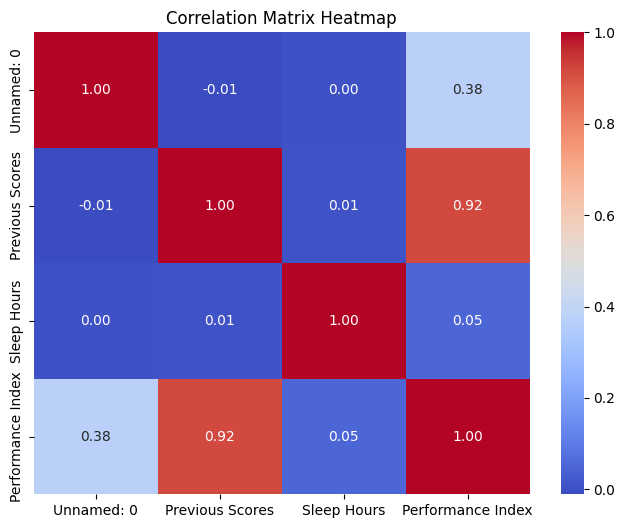

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

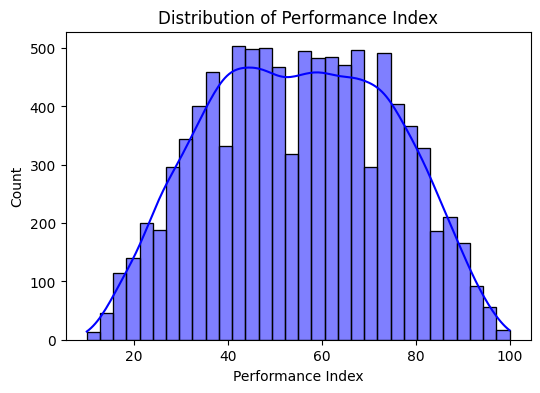

In [15]:
plt.figure(figsize=(6, 4))
sns.histplot(df['Performance Index'], kde=True, color='blue')
plt.title("Distribution of Performance Index")
plt.show()

In [16]:
from sklearn.preprocessing import OneHotEncoder
onehotencoder = OneHotEncoder()
W = onehotencoder.fit_transform(df[['Extracurricular Activities']]).toarray()

for ind, col in enumerate(onehotencoder.categories_[0]):
    df[col] = W[:, ind]
    print(ind, col)

df.drop('Extracurricular Activities', axis=1, inplace=True)
df.columns = df.columns.astype(str)

0 No
1 Yes


In [17]:
y = df['Performance Index']
X = df.drop(columns=['Performance Index'])

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nTraining set shape (X_train):", X_train.shape)
print("Testing set shape (X_test):", X_test.shape)


Training set shape (X_train): (7894, 5)
Testing set shape (X_test): (1974, 5)


In [27]:
import re

for d in (X_train, X_test):
    d.columns = [re.sub(r'[^0-9a-zA-Z_]', '_', c) for c in d.columns]

print(X_train.columns)

Index(['Unnamed__0', 'Previous_Scores', 'Sleep_Hours', 'No', 'Yes'], dtype='object')


In [19]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('\nMAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2: ', r2_score(y_test, y_pred))


MAE:  1.7033645599930531
MSE:  4.531481415922674
RMSE:  2.1287276518903666
R2:  0.9880179657376145


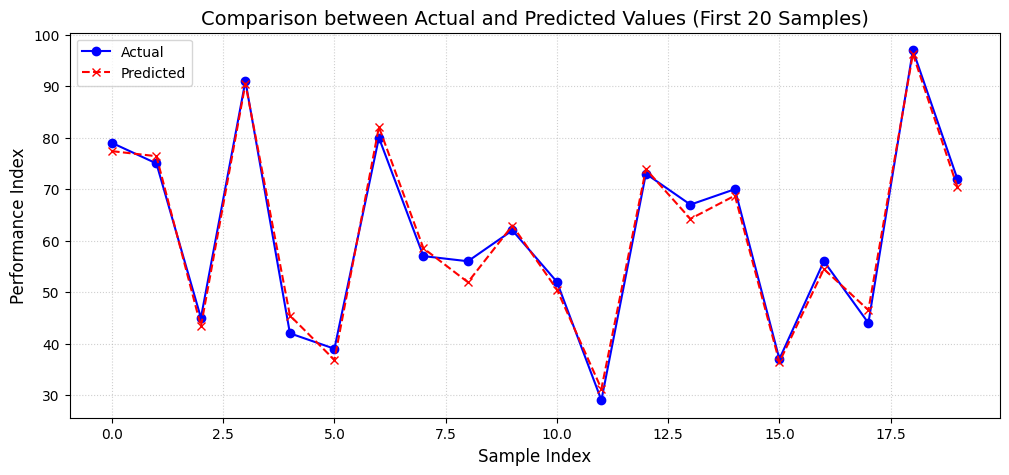

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:20], marker='o', linestyle='-', color='blue', label='Actual')
plt.plot(y_pred[:20], marker='x', linestyle='--', color='red', label='Predicted')

plt.xlabel('Sample Index', fontsize=12)
plt.ylabel('Performance Index', fontsize=12)
plt.title('Comparison between Actual and Predicted Values (First 20 Samples)', fontsize=14)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

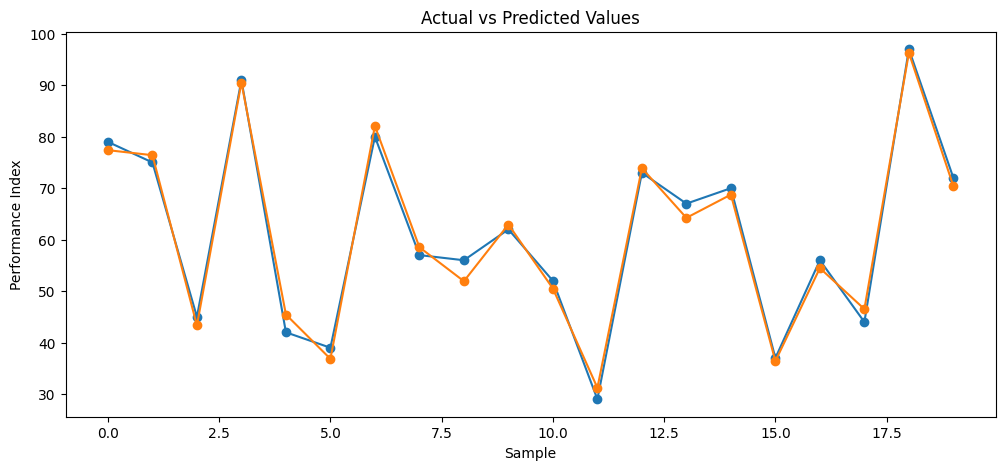

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:20], marker='o', label='Actual')
plt.plot(y_pred[:20], marker='o', label='Predicted')

plt.xlabel('Sample')
plt.ylabel('Performance Index')
plt.title('Actual vs Predicted Values')

plt.show()

In [24]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [25]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [28]:
import time
from joblib import Parallel, delayed

# 1) شيلي SVM (أبطأ موديل) أو استبدليه بـ LinearSVR
from sklearn.svm import LinearSVR

models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, p=1, n_jobs=-1),
    "LinearSVR": LinearSVR(C=100, max_iter=2000, random_state=42),   # بدل SVR
    "Decision Tree": DecisionTreeRegressor(max_depth=10),
    "Random Forest": RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=10),
                                n_estimators=50, n_jobs=-1, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0, n_jobs=-1),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42, thread_count=-1),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1),
}

def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    mse = mean_squared_error(y_actual, y_pred)
    return mean_absolute_error(y_actual, y_pred), mse, np.sqrt(mse), r2_score(y_actual, y_pred)

def fit_and_eval(name, model):
    model.fit(X_train, y_train)
    tr = regression_metrics(model, X_train, y_train)
    te = regression_metrics(model, X_test, y_test)
    return name, model, {
        "MAE Train": tr[0], "MAE Test": te[0],
        "MSE Train": tr[1], "MSE Test": te[1],
        "RMSE Train": tr[2], "RMSE Test": te[2],
        "R2 Train": tr[3], "R2 Test": te[3],
    }

# 2) تدريب كل الموديلات بالتوازي
start = time.time()
results = Parallel(n_jobs=-1)(delayed(fit_and_eval)(n, clone(m)) for n, m in models.items())
errors = {name: metrics for name, _, metrics in results}
fitted = {name: m for name, m, _ in results}
print(f"Done in {time.time()-start:.1f}s")

Done in 10.1s


In [29]:
# Voting: model1 و model2 نفس الحاجة بالظبط، فاعملي واحد بس
rf  = RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=1)
voting = VotingRegressor([('lr', LinearRegression()), ('rf', rf), ('dt', DecisionTreeRegressor(random_state=1))], n_jobs=-1)
w_voting = VotingRegressor([('lr', LinearRegression()), ('rf', rf), ('dt', DecisionTreeRegressor(random_state=1))],
                           weights=[2, 1, 2], n_jobs=-1)

for name, m in [("Voting", voting), ("Weighted Voting", w_voting)]:
    _, _, errors[name] = fit_and_eval(name, m)


In [30]:
stacking = StackingRegressor(
    estimators=[
        ('rf',  RandomForestRegressor(n_estimators=30, n_jobs=-1, random_state=42)),
        ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1)),
        ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0, random_state=42)),
    ],
    final_estimator=Ridge(),   # بدل XGBoost: أسرع وكفاية للـ meta
    cv=3,
    n_jobs=-1
)
_, _, errors["Stacking"] = fit_and_eval("Stacking", stacking)

Best model: Ridge


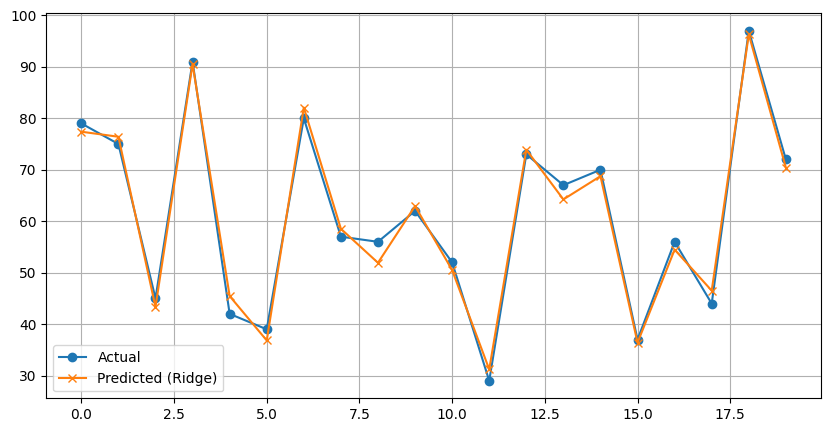

In [31]:
best = max(errors, key=lambda k: errors[k]["R2 Test"])
print("Best model:", best)
plt.figure(figsize=(10,5))
plt.plot(y_test.values[:20], marker='o', label='Actual')
plt.plot(fitted[best].predict(X_test[:20]), marker='x', label=f'Predicted ({best})')
plt.legend(); plt.grid(); plt.show()

In [32]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [33]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Ridge,1.686656,1.703363,4.511433,4.531473,2.124013,2.128726,0.987710,0.988018
Linear Regression,1.686655,1.703365,4.511433,4.531481,2.124013,2.128728,0.987710,0.988018
CatBoost,1.682868,1.746997,4.488501,4.743508,2.118608,2.177960,0.987773,0.987457
Stacking,1.650407,1.760322,4.309383,4.785240,2.075905,2.187519,0.988261,0.987347
GradientBoosting,1.679872,1.769500,4.474039,4.851293,2.115192,2.202565,0.987812,0.987172
HistGradientBoosting,1.604006,1.775025,4.067942,4.882756,2.016914,2.209696,0.988918,0.987089
LightGBM,1.604006,1.775093,4.067942,4.882908,2.016914,2.209730,0.988918,0.987089
XGBoost,1.553182,1.796293,3.820783,5.013054,1.954682,2.238985,0.989592,0.986745
Lasso,1.785776,1.807858,5.067426,5.059522,2.251094,2.249338,0.986195,0.986622
LinearSVR,1.807174,1.832739,5.119414,5.276892,2.262612,2.297149,0.986054,0.986047


<Axes: >

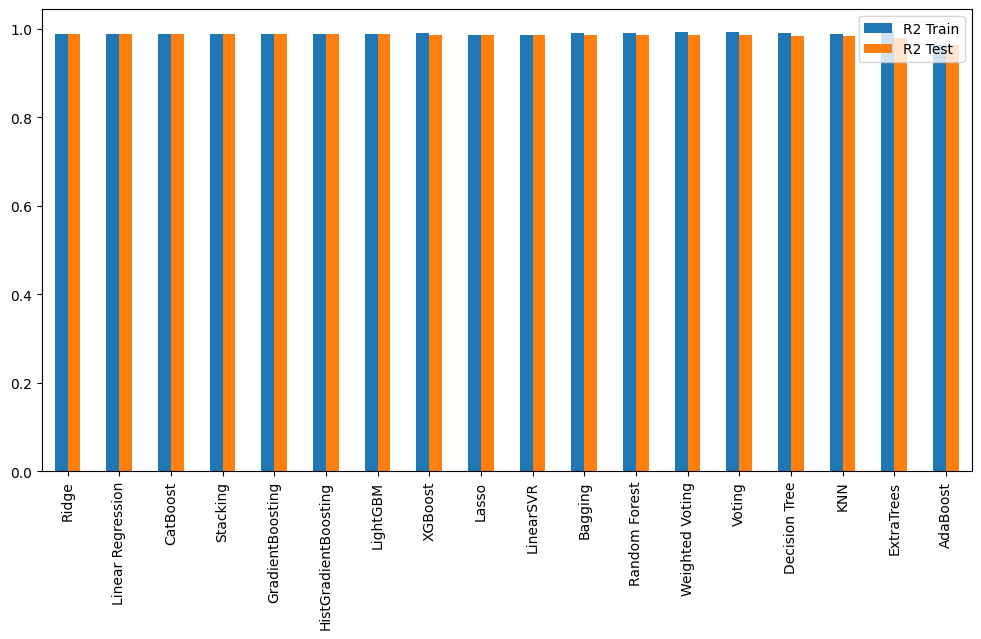

In [34]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

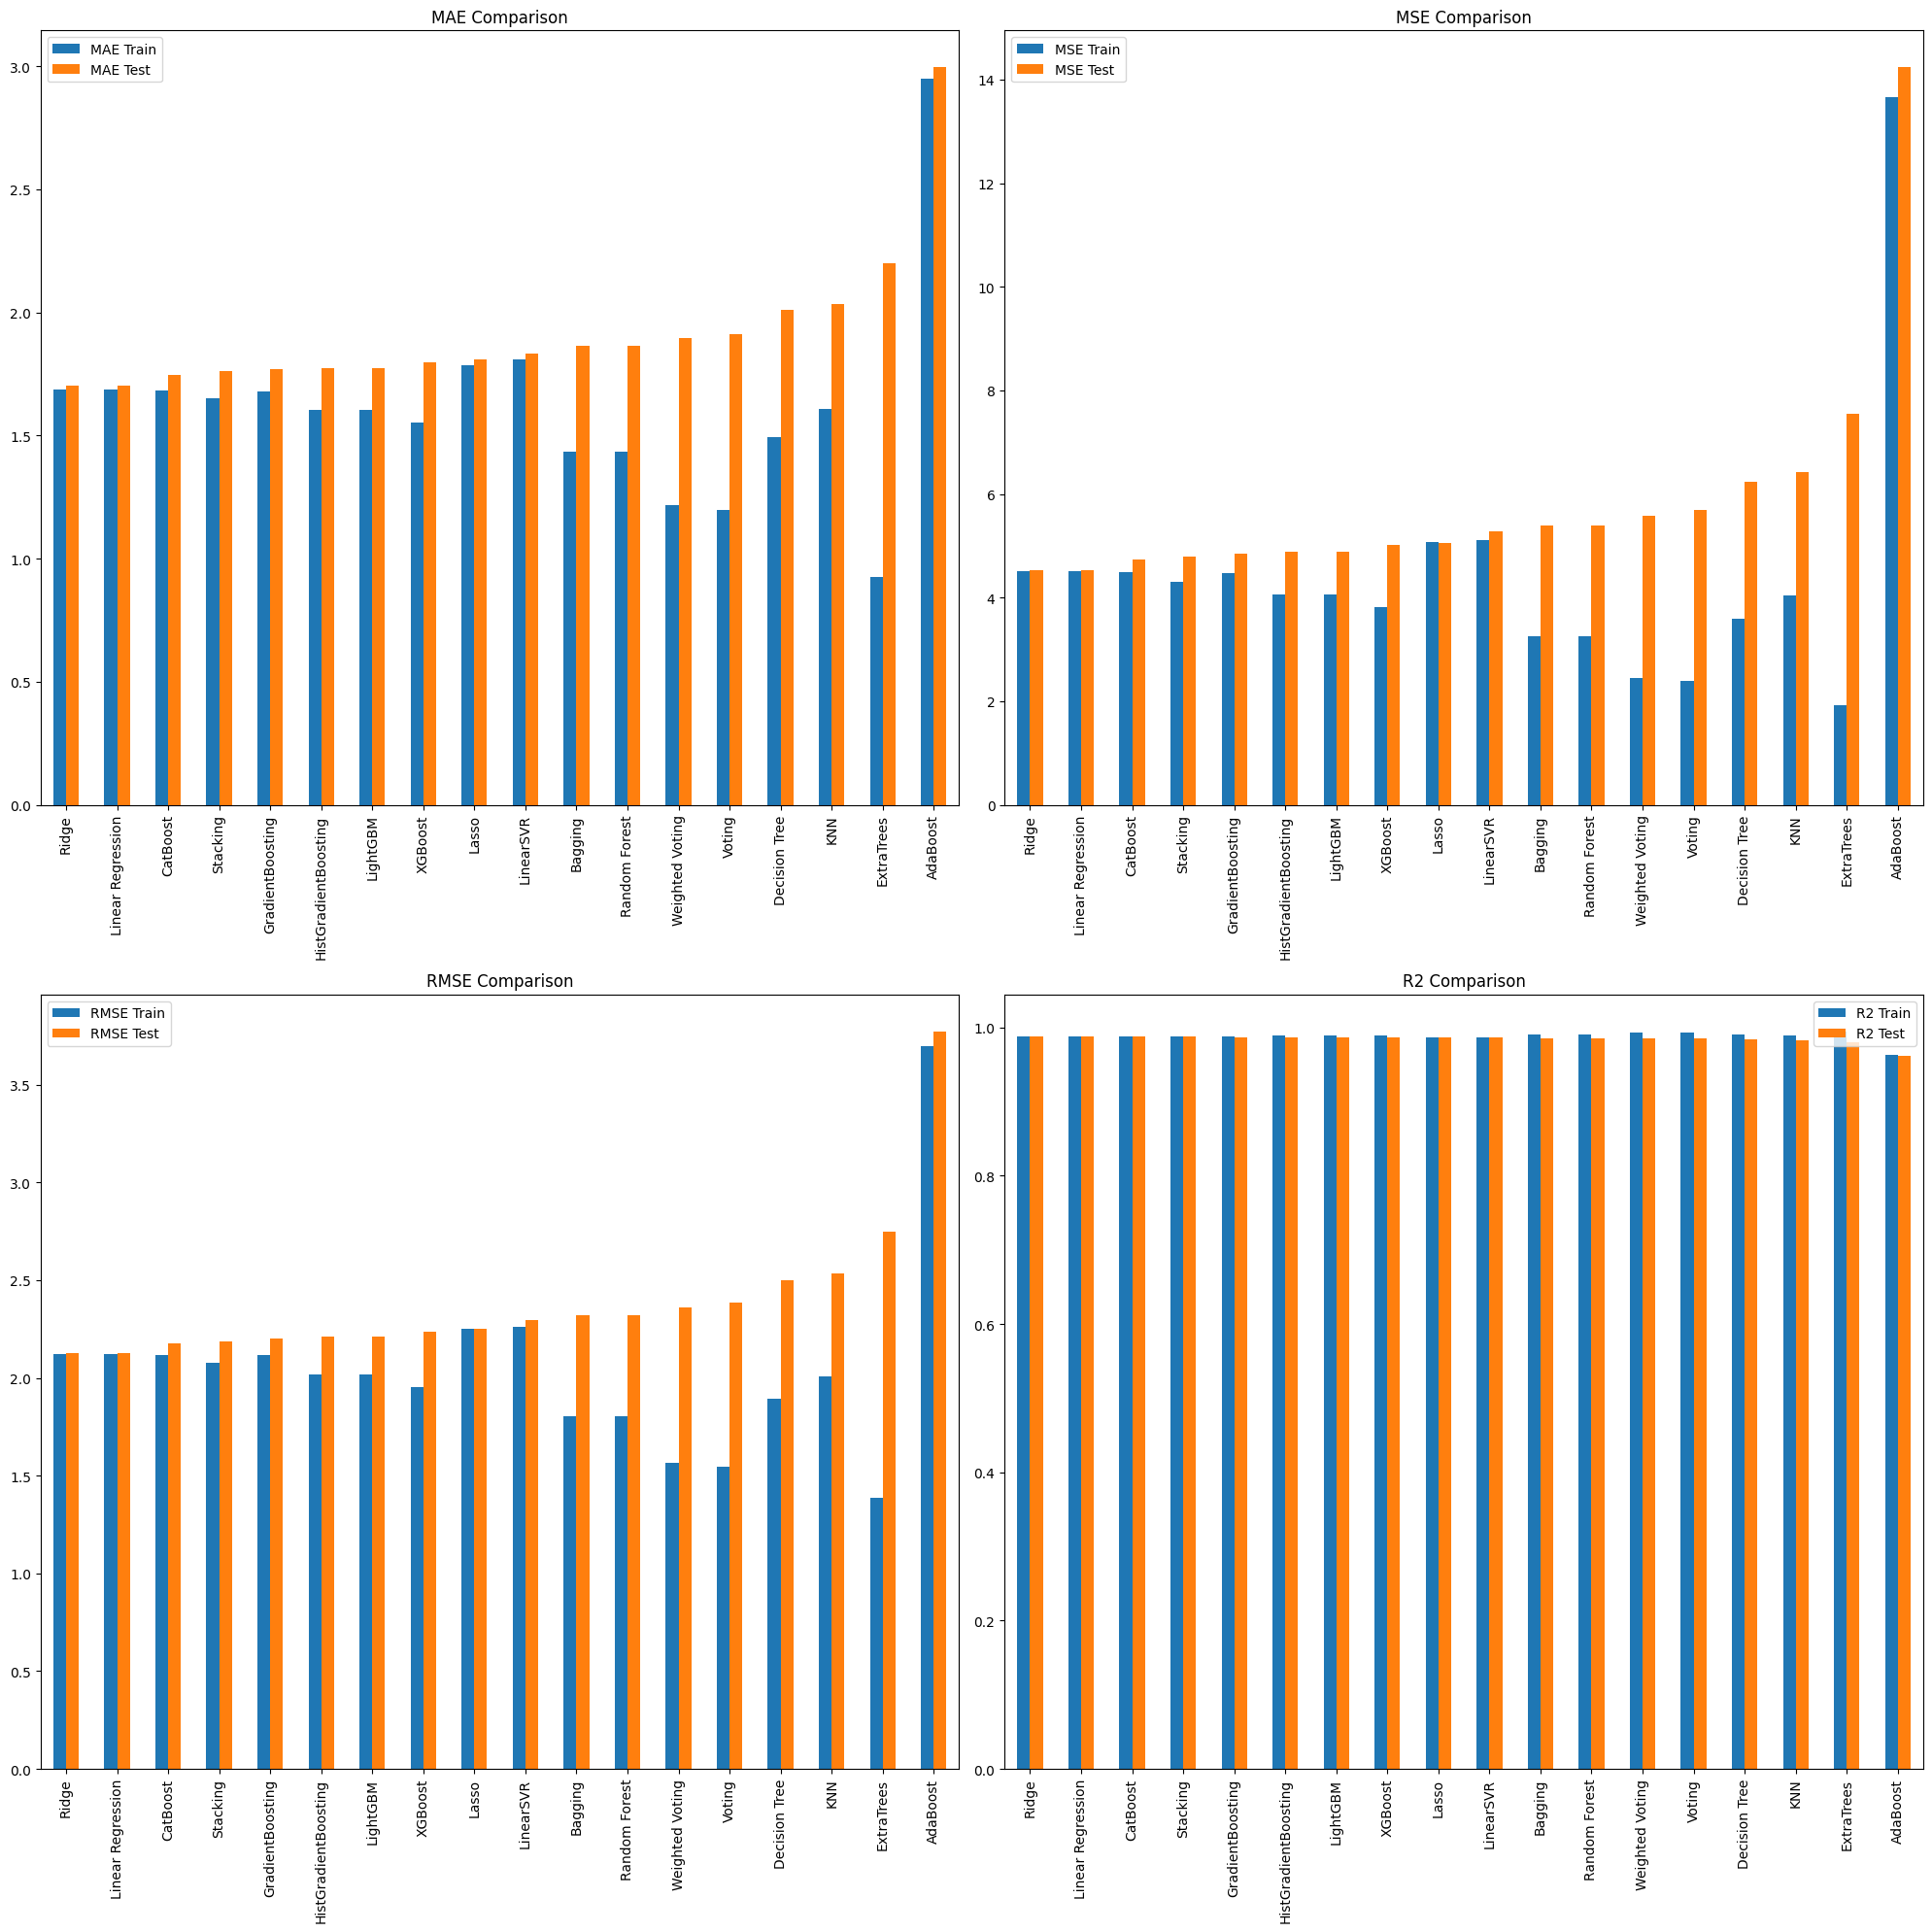

In [35]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()